# A/B Test Analysis: Does Moving a Game Gate Change Player Retention?

**Dataset:** Cookie Cats mobile game A/B test (Kaggle: "Mobile Games A/B Testing - Cookie Cats"). About 90k players were randomly split into two versions of the game: the first gate placed at level 30 (`gate_30`, control) or level 40 (`gate_40`, treatment).

**Question:** Does moving the gate from level 30 to level 40 change 1-day retention, 7-day retention, or engagement (game rounds played)? Should the product team ship it?

**What this notebook covers:** data sanity checks, sample-ratio check, SQL analysis, two-proportion z-test, bootstrap confidence intervals, Mann-Whitney test for skewed data, multiple-testing correction, power analysis, a Bayesian view, and a simulation that shows why peeking at results early is dangerous.

**How to use:** download `cookie_cats.csv` from Kaggle, keep it next to this notebook, run top to bottom, then write your own conclusion in the last cell using YOUR numbers. Do not copy any number that you did not see in your own output.

**Chem Eng lens used throughout:** an A/B test is a control batch vs a trial batch run under identical conditions except for ONE changed variable (here, the gate level, like changing only the catalyst).

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)   # fixed seed so your results are reproducible
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Load data and sanity checks

*Chem Eng analogy:* before trusting a batch report, you check the sensors. Missing values, duplicate records and absurd readings are the data version of a faulty sensor.

In [2]:
DATA_PATH = "cookie_cats.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate user ids:", df.userid.duplicated().sum())
print("\nPlayers per version:\n", df.version.value_counts())
print("\nGame rounds summary:\n", df.sum_gamerounds.describe())

print("\nTop 5 heaviest players (possible outliers / bots):")
df.sort_values("sum_gamerounds", ascending=False).head(5)

Shape: (90189, 5)

Missing values per column:
 userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Duplicate user ids: 0

Players per version:
 version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Game rounds summary:
 count   90,189.0000
mean        51.8725
std        195.0509
min          0.0000
25%          5.0000
50%         16.0000
75%         51.0000
max     49,854.0000
Name: sum_gamerounds, dtype: float64

Top 5 heaviest players (possible outliers / bots):


,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


## 2. Sample Ratio Mismatch (SRM) check

If the split was meant to be 50/50, the group sizes should be close. A big mismatch means the randomisation is broken and every later result is suspect.

*Chem Eng analogy:* you intended to split the feed equally between two reactors. If one reactor got noticeably more feed, you cannot compare their yields fairly.

In [3]:
counts = df.version.value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts.values)   # expected = equal split
print(counts.to_string())
print(f"\nChi-square = {chi2:.3f}, p = {p_srm:.4f}")
print("SRM warning: split looks unequal!" if p_srm < 0.01 else "No evidence of sample ratio mismatch.")

version
gate_30    44700
gate_40    45489

Chi-square = 6.902, p = 0.0086
SRM warning: split looks unequal!


## 3. SQL analysis (SQLite)

Data scientists query data with SQL first. Here the same DataFrame is loaded into an in-memory SQLite database.

In [4]:
con = sqlite3.connect(":memory:")
df.to_sql("players", con, index=False, if_exists="replace")

# Query 1: headline metrics per version
q1 = """
SELECT version,
       COUNT(*)                      AS players,
       ROUND(AVG(retention_1), 4)    AS ret_day1,
       ROUND(AVG(retention_7), 4)    AS ret_day7,
       ROUND(AVG(sum_gamerounds), 2) AS avg_rounds
FROM players
GROUP BY version;
"""
print(pd.read_sql(q1, con))

# Query 2: window function (NTILE) to split players into engagement quartiles within each version
q2 = """
WITH ranked AS (
    SELECT version, retention_7,
           NTILE(4) OVER (PARTITION BY version ORDER BY sum_gamerounds) AS engagement_quartile
    FROM players
)
SELECT version, engagement_quartile,
       COUNT(*)                   AS players,
       ROUND(AVG(retention_7), 4) AS ret_day7
FROM ranked
GROUP BY version, engagement_quartile
ORDER BY engagement_quartile, version;
"""
pd.read_sql(q2, con)

   version  players  ret_day1  ret_day7  avg_rounds
0  gate_30    44700    0.4482    0.1902     52.4600
1  gate_40    45489    0.4423    0.1820     51.3000


,version,engagement_quartile,players,ret_day7
0,gate_30,1,11175,0.0117
1,gate_40,1,11373,0.0123
2,gate_30,2,11175,0.0402
3,gate_40,2,11372,0.0378
4,gate_30,3,11175,0.1467
5,gate_40,3,11372,0.1322
6,gate_30,4,11175,0.5622
7,gate_40,4,11372,0.5457


## 4. Retention: two-proportion z-test with confidence intervals

Retention is a yes/no outcome per player, so we compare two proportions.

- **p-value:** if moving the gate truly did nothing, how likely is a difference this large just from random noise? *(Chem Eng: is the yield difference caused by the catalyst, or just batch-to-batch scatter?)*
- **Confidence interval (CI):** the error bars on the measured difference.
- **Bonferroni correction:** we look at 3 metrics (day-1 retention, day-7 retention, game rounds). The more outputs you test, the more likely one looks significant by luck, so we tighten the threshold to 0.05 / 3. *(Like a plant with many alarms: some will fire falsely.)*

In [5]:
def two_prop_ztest(x1, n1, x2, n2):
    """Control = group 1, treatment = group 2. Returns diff, z, p-value, 95% CI of the difference."""
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p2 - p1) / se_pool
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    se_unpooled = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    ci = ((p2 - p1) - 1.96 * se_unpooled, (p2 - p1) + 1.96 * se_unpooled)
    return p2 - p1, z, p_value, ci

A = df[df.version == "gate_30"]   # control
B = df[df.version == "gate_40"]   # treatment

rows = []
for metric in ["retention_1", "retention_7"]:
    xa, na = int(A[metric].sum()), len(A)
    xb, nb = int(B[metric].sum()), len(B)
    diff, z, p, ci = two_prop_ztest(xa, na, xb, nb)
    rows.append(dict(metric=metric, rate_gate_30=xa / na, rate_gate_40=xb / nb,
                     diff_40_minus_30=diff, z=z, p_value=p, ci_low=ci[0], ci_high=ci[1]))

res = pd.DataFrame(rows)
ALPHA, N_TESTS = 0.05, 3
res["significant_at_0.05"] = res.p_value < ALPHA
res["significant_after_bonferroni"] = res.p_value < ALPHA / N_TESTS
res

,metric,rate_gate_30,rate_gate_40,diff_40_minus_30,z,p_value,ci_low,ci_high,significant_at_0.05,significant_after_bonferroni
0,retention_1,0.4482,0.4423,-0.0059,-1.7841,0.0744,-0.0124,0.0006,False,False
1,retention_7,0.1902,0.1820,-0.0082,-3.1644,0.0016,-0.0133,-0.0031,True,True


## 5. Engagement (game rounds): skewed data needs different tools

Game rounds are heavily right-skewed (a few players play thousands of rounds). A plain t-test is fragile here, so we use:
- **Winsorising** (cap extreme values at the 99.9th percentile),
- **Mann-Whitney U test** (compares distributions without assuming a bell curve),
- **Bootstrap CI** (resample the data many times to see how much the mean or median difference wobbles).

*Chem Eng analogy:* a single spike from a faulty sensor should not decide the batch result, so you cap or down-weight it.

In [6]:
a = A.sum_gamerounds.values.astype(float)
b = B.sum_gamerounds.values.astype(float)

cap = np.percentile(df.sum_gamerounds, 99.9)
a_w, b_w = np.minimum(a, cap), np.minimum(b, cap)

u_stat, p_mw = stats.mannwhitneyu(a_w, b_w, alternative="two-sided")
print(f"Winsorising cap (99.9th percentile): {cap:,.0f} rounds")
print(f"Mann-Whitney U p-value: {p_mw:.4f}  (Bonferroni threshold = {ALPHA / N_TESTS:.4f})")

def bootstrap_diff(x, y, stat=np.mean, n_boot=2000):
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        diffs[i] = stat(rng.choice(y, size=len(y))) - stat(rng.choice(x, size=len(x)))
    return diffs

d_mean = bootstrap_diff(a_w, b_w, np.mean)
d_med = bootstrap_diff(a_w, b_w, np.median)
for name, d in [("mean", d_mean), ("median", d_med)]:
    lo, hi = np.percentile(d, [2.5, 97.5])
    print(f"Bootstrap 95% CI for difference in {name} rounds (gate_40 - gate_30): [{lo:.3f}, {hi:.3f}]")

Winsorising cap (99.9th percentile): 1,074 rounds
Mann-Whitney U p-value: 0.0502  (Bonferroni threshold = 0.0167)
Bootstrap 95% CI for difference in mean rounds (gate_40 - gate_30): [-1.286, 1.205]
Bootstrap 95% CI for difference in median rounds (gate_40 - gate_30): [-1.000, 0.000]


## 6. Power analysis: was the test big enough?

**Power** = the probability that the test detects a real effect of a given size. A small effect needs a big sample.

*Chem Eng analogy:* the detection limit of an analytical instrument. To detect a tiny change in concentration you need a more sensitive instrument (here, more samples).

In [7]:
def sample_size_per_group(p_base, mde_abs, alpha=0.05, power=0.80):
    """Players needed per group to detect an absolute lift of mde_abs over baseline rate p_base."""
    p2 = p_base + mde_abs
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    var = p_base * (1 - p_base) + p2 * (1 - p2)
    return int(np.ceil(((z_a + z_b) ** 2) * var / (mde_abs ** 2)))

def min_detectable_effect(p_base, n_per_group, alpha=0.05, power=0.80):
    """Approximate smallest absolute lift detectable with n_per_group players per group."""
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p_base * (1 - p_base) / n_per_group)

p7 = A.retention_7.mean()
print(f"Baseline day-7 retention (gate_30): {p7:.4f}")
for mde in [0.01, 0.005, 0.002]:
    print(f"To detect a +{mde * 100:.1f} percentage-point lift you need about "
          f"{sample_size_per_group(p7, mde):,} players per group")
print(f"\nWith {len(A):,} players per group, the minimum detectable lift is about "
      f"{min_detectable_effect(p7, len(A)) * 100:.2f} percentage points.")

Baseline day-7 retention (gate_30): 0.1902
To detect a +1.0 percentage-point lift you need about 24,657 players per group
To detect a +0.5 percentage-point lift you need about 97,679 players per group
To detect a +0.2 percentage-point lift you need about 606,885 players per group

With 44,700 players per group, the minimum detectable lift is about 0.74 percentage points.


## 7. Bayesian view: "how likely is gate_40 actually better?"

Instead of a p-value, the Bayesian approach gives a direct probability. We model each retention rate with a Beta distribution (starting from a flat prior) and update it with the observed data.

*Chem Eng analogy:* like updating your belief about a rate constant after each experiment, instead of only asking whether it rejects a null hypothesis.

In [8]:
def beta_posterior_diff(xa, na, xb, nb, n_draws=200_000):
    pa = rng.beta(1 + xa, 1 + na - xa, n_draws)
    pb = rng.beta(1 + xb, 1 + nb - xb, n_draws)
    return pb - pa

for metric in ["retention_1", "retention_7"]:
    diff_samples = beta_posterior_diff(int(A[metric].sum()), len(A), int(B[metric].sum()), len(B))
    lo, hi = np.percentile(diff_samples, [2.5, 97.5])
    print(f"{metric}: P(gate_40 better than gate_30) = {(diff_samples > 0).mean():.3f}; "
          f"95% credible interval of difference = [{lo:.4f}, {hi:.4f}]")
    if metric == "retention_7":
        diff7 = diff_samples

retention_1: P(gate_40 better than gate_30) = 0.038; 95% credible interval of difference = [-0.0124, 0.0006]
retention_7: P(gate_40 better than gate_30) = 0.001; 95% credible interval of difference = [-0.0133, -0.0031]


## 8. Why you should not peek: an A/A simulation

An **A/A test** compares two identical groups, so any "significant" result is a false alarm. If you check the p-value many times and stop the moment it dips below 0.05, false alarms explode.

*Chem Eng analogy:* checking the batch yield every hour and stopping the experiment as soon as it "looks good". You will often stop on random noise.

In [9]:
def peeking_false_positive_rate(n_sims=1000, n=10_000, p=0.2, looks=10):
    a_ = rng.random((n_sims, n)) < p
    b_ = rng.random((n_sims, n)) < p
    checkpoints = np.linspace(n / looks, n, looks).astype(int)
    any_hit = np.zeros(n_sims, dtype=bool)
    last_hit = np.zeros(n_sims, dtype=bool)
    for k in checkpoints:
        x1, x2 = a_[:, :k].sum(1), b_[:, :k].sum(1)
        p_pool = (x1 + x2) / (2 * k)
        se = np.sqrt(p_pool * (1 - p_pool) * 2 / k)
        z = (x2 / k - x1 / k) / se
        hit = np.abs(z) > 1.96
        any_hit |= hit
        last_hit = hit
    return any_hit.mean(), last_hit.mean()

peek_fp, final_fp = peeking_false_positive_rate()
print(f"False positive rate when stopping at the FIRST significant peek (10 looks): {peek_fp:.1%}")
print(f"False positive rate when testing ONCE at the planned end:                  {final_fp:.1%}")

False positive rate when stopping at the FIRST significant peek (10 looks): 17.7%
False positive rate when testing ONCE at the planned end:                  4.5%


## 9. Visual summary

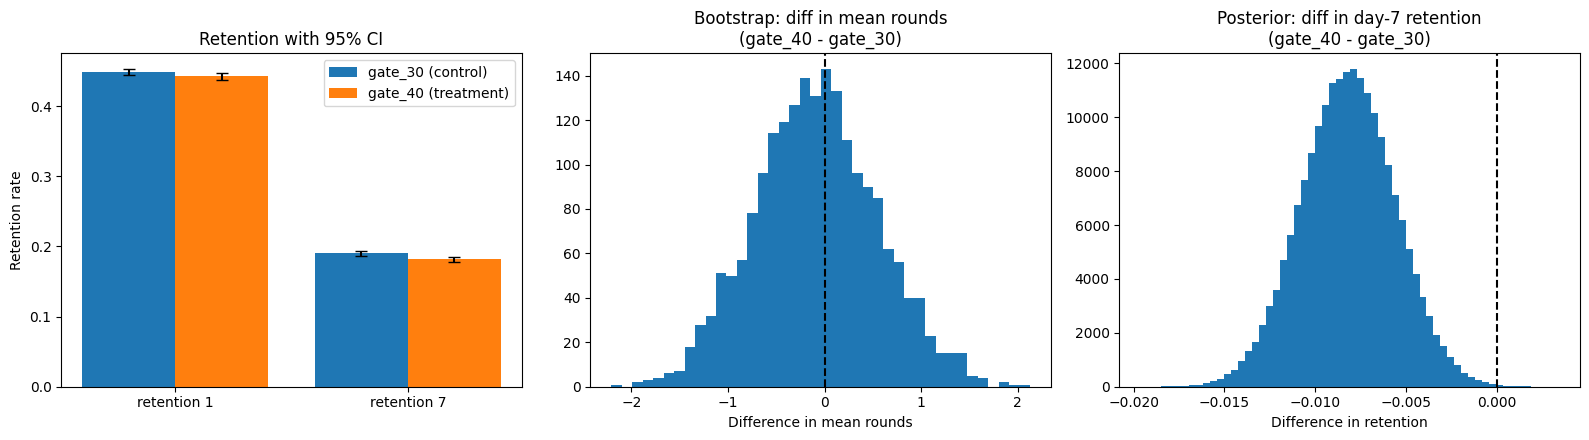

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) retention rates with 95% CI error bars
labels, rates, errs = [], {"gate_30": [], "gate_40": []}, {"gate_30": [], "gate_40": []}
for metric in ["retention_1", "retention_7"]:
    labels.append(metric.replace("_", " "))
    for name, grp in [("gate_30", A), ("gate_40", B)]:
        p_hat = grp[metric].mean()
        rates[name].append(p_hat)
        errs[name].append(1.96 * np.sqrt(p_hat * (1 - p_hat) / len(grp)))
x = np.arange(len(labels))
axes[0].bar(x - 0.2, rates["gate_30"], 0.4, yerr=errs["gate_30"], capsize=4, label="gate_30 (control)")
axes[0].bar(x + 0.2, rates["gate_40"], 0.4, yerr=errs["gate_40"], capsize=4, label="gate_40 (treatment)")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Retention rate"); axes[0].set_title("Retention with 95% CI"); axes[0].legend()

# (b) bootstrap distribution of the difference in mean game rounds
axes[1].hist(d_mean, bins=40)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Bootstrap: diff in mean rounds\n(gate_40 - gate_30)")
axes[1].set_xlabel("Difference in mean rounds")

# (c) Bayesian posterior of the day-7 retention difference
axes[2].hist(diff7, bins=60)
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set_title("Posterior: diff in day-7 retention\n(gate_40 - gate_30)")
axes[2].set_xlabel("Difference in retention")

plt.tight_layout()
plt.savefig("ab_test_summary.png", dpi=150)
plt.show()

## 10. Business recommendation (WRITE THIS YOURSELF using YOUR output)

Fill in the blanks after running every cell. Keep it in plain English, as if explaining to a product manager.

- **Randomisation check:** the SRM test gave p = ___ , so the split looks ___ .
- **Day-1 retention:** gate_30 = ___ , gate_40 = ___ , difference = ___ (95% CI ___ to ___ ), p = ___ .
- **Day-7 retention:** gate_30 = ___ , gate_40 = ___ , difference = ___ (95% CI ___ to ___ ), p = ___ . After Bonferroni, this is / is not significant.
- **Engagement:** mean/median rounds difference = ___ (bootstrap 95% CI ___ ).
- **Bayesian:** probability that gate_40 is better on day-7 retention = ___ .
- **Power:** our sample could detect a lift of about ___ percentage points; smaller effects could be missed.
- **Decision:** ship gate_40 / keep gate_30 / run a longer or larger test, because ___ .
- **Risks and next steps:** (for example: check guardrail metrics like revenue, test other gate positions, look at player segments).